# Yelp Reviews: Exploratory Data Analysis and Text Classification

Explores a Yelp reviews dataset and builds a binary text classifier for extreme ratings. It combines descriptive analysis of ratings, review length, and voting features with a comparison of bag-of-words and TF–IDF Multinomial Naive Bayes models.

**Dataset used in this notebook:** a local file named `yelp.csv` containing 10,000 reviews. The notebook does not record the dataset's source URL or license; add those details before publishing the project.

## Objectives
- Inspect the structure and completeness of the review data.
- Explore how review length and review-vote features vary by star rating.
- Compare 1-star and 5-star review text with simple, reproducible classification baselines.



In [1]:
import numpy as np
import pandas as pd
import sklearn

## Data

In [2]:
df = pd.read_csv('data/yelp.csv')
df.head()

,business_id,date,review_id,stars,text,type,user_id,cool,useful,funny
0,9yKzy9PApeiPPOUJEtnvkg,2011-01-26,fWKvX83p0-ka4JS3dc6E5A,5,My wife took me here on my birthday for breakf...,review,rLtl8ZkDX5vH5nAx9C3q5Q,2,5,0
1,ZRJwVLyzEJq1VAihDhYiow,2011-07-27,IjZ33sJrzXqU-0X6U8NwyA,5,I have no idea why some people give bad review...,review,0a2KyEL0d3Yb1V6aivbIuQ,0,0,0
2,6oRAC4uyJCsJl1X0WZpVSA,2012-06-14,IESLBzqUCLdSzSqm0eCSxQ,4,love the gyro plate. Rice is so good and I als...,review,0hT2KtfLiobPvh6cDC8JQg,0,1,0
3,_1QQZuf4zZOyFCvXc0o6Vg,2010-05-27,G-WvGaISbqqaMHlNnByodA,5,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",review,uZetl9T0NcROGOyFfughhg,1,2,0
4,6ozycU1RpktNG2-1BroVtw,2012-01-05,1uJFq2r5QfJG_6ExMRCaGw,5,General Manager Scott Petello is a good egg!!!...,review,vYmM4KTsC8ZfQBg-j5MWkw,0,0,0


### Initial inspection

Check the number of records, column types, and missing values. The original notebook output shows 10,000 entries and no missing values in the original 10 columns.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   business_id  10000 non-null  str  
 1   date         10000 non-null  str  
 2   review_id    10000 non-null  str  
 3   stars        10000 non-null  int64
 4   text         10000 non-null  str  
 5   type         10000 non-null  str  
 6   user_id      10000 non-null  str  
 7   cool         10000 non-null  int64
 8   useful       10000 non-null  int64
 9   funny        10000 non-null  int64
dtypes: int64(4), str(6)
memory usage: 781.4 KB


In [4]:
df.describe()

,stars,cool,useful,funny
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,3.777500,0.876800,1.409300,0.701300
std,1.214636,2.067861,2.336647,1.907942
min,1.000000,0.000000,0.000000,0.000000
25%,3.000000,0.000000,0.000000,0.000000
50%,4.000000,0.000000,1.000000,0.000000
75%,5.000000,1.000000,2.000000,1.000000
max,5.000000,77.000000,76.000000,57.000000


### Feature engineering: review length

`text_length` is the number of characters in each review. This derived feature is used to compare how much users write at different rating levels.

In [5]:
df['text_length'] = df.text.apply(len)
df.head()

,business_id,date,review_id,stars,text,type,user_id,cool,useful,funny,text_length
0,9yKzy9PApeiPPOUJEtnvkg,2011-01-26,fWKvX83p0-ka4JS3dc6E5A,5,My wife took me here on my birthday for breakf...,review,rLtl8ZkDX5vH5nAx9C3q5Q,2,5,0,889
1,ZRJwVLyzEJq1VAihDhYiow,2011-07-27,IjZ33sJrzXqU-0X6U8NwyA,5,I have no idea why some people give bad review...,review,0a2KyEL0d3Yb1V6aivbIuQ,0,0,0,1345
2,6oRAC4uyJCsJl1X0WZpVSA,2012-06-14,IESLBzqUCLdSzSqm0eCSxQ,4,love the gyro plate. Rice is so good and I als...,review,0hT2KtfLiobPvh6cDC8JQg,0,1,0,76
3,_1QQZuf4zZOyFCvXc0o6Vg,2010-05-27,G-WvGaISbqqaMHlNnByodA,5,"Rosie, Dakota, and I LOVE Chaparral Dog Park!!...",review,uZetl9T0NcROGOyFfughhg,1,2,0,419
4,6ozycU1RpktNG2-1BroVtw,2012-01-05,1uJFq2r5QfJG_6ExMRCaGw,5,General Manager Scott Petello is a good egg!!!...,review,vYmM4KTsC8ZfQBg-j5MWkw,0,0,0,469


## Exploratory Data Analysis

This section examines the distribution of review length and ratings, then summarizes numeric review characteristics by star rating. These are descriptive comparisons; they do not establish causal relationships.

In [6]:
import seaborn as sns
sns.set_style('whitegrid')
import matplotlib.pyplot as plt
%matplotlib inline

### Review length across ratings

The faceted histograms and box plot make it possible to compare the distribution, spread, and potential outliers of review length for each 1–5 star group.

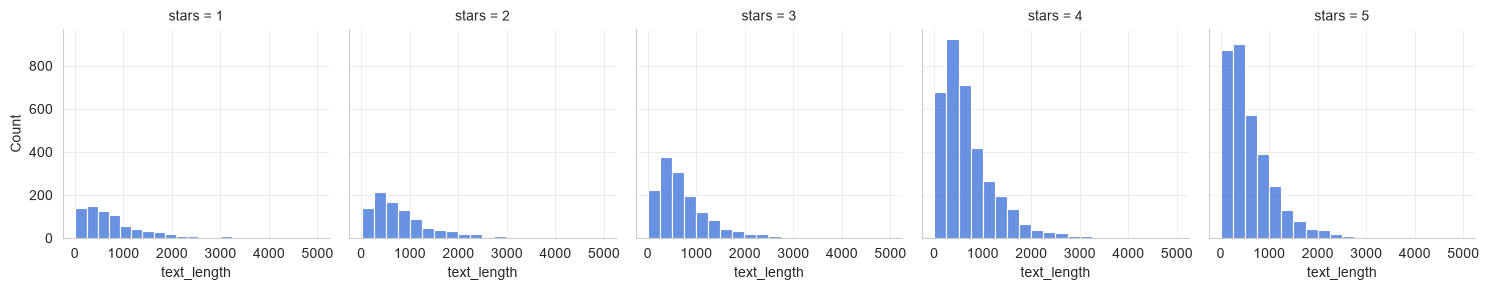

In [7]:
sns.FacetGrid(df, col="stars").map(sns.histplot, "text_length", bins=20)

<Axes: xlabel='stars', ylabel='text_length'>

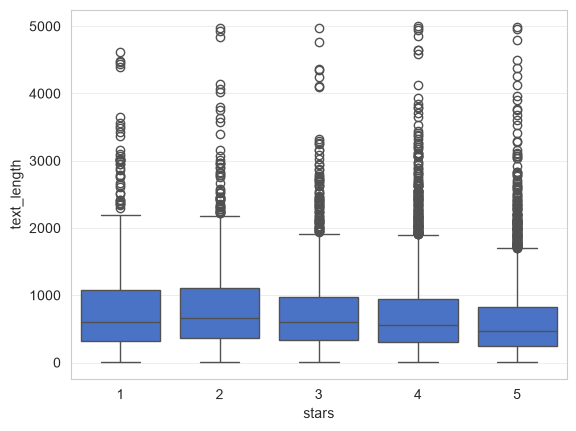

In [8]:
sns.boxplot(df, x="stars", y="text_length")

### Rating distribution

The count plot shows how many reviews fall into each star category. This is important context for interpreting later model metrics, because uneven rating groups can make accuracy alone misleading.

<Axes: xlabel='stars', ylabel='count'>

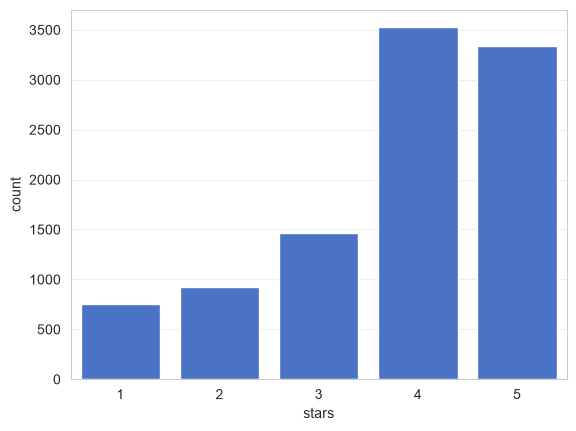

In [9]:
sns.countplot(df, x ="stars")

### Rating-level numeric summaries

Group the data by `stars` and calculate the average vote counts and average review length. This produces a compact view of how review characteristics differ across ratings.

In [10]:
gb_stars = df.groupby("stars").mean(numeric_only=True)
gb_stars

,cool,useful,funny,text_length
stars,,,,
1,0.576769,1.604806,1.056075,826.515354
2,0.719525,1.563107,0.875944,842.256742
3,0.788501,1.306639,0.694730,758.498289
4,0.954623,1.395916,0.670448,712.923142
5,0.944261,1.381780,0.608631,624.999101


### Relationships among rating-level averages

The heatmap below correlates the group means calculated above. Because it uses five star-rating groups rather than individual reviews, interpret it as a high-level exploratory summary only.

<Axes: >

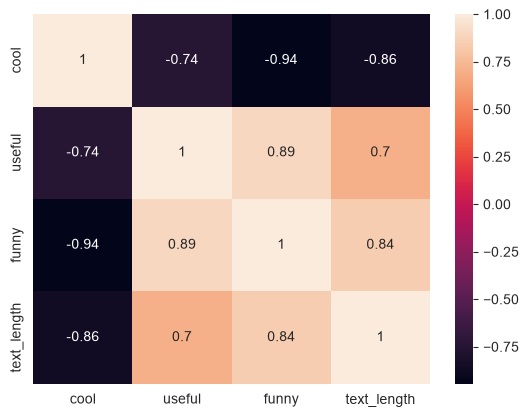

In [11]:
sns.heatmap(gb_stars.corr(), annot=True )

## Binary Text Classification: 1-Star vs. 5-Star Reviews

To create a focused classification task, the notebook keeps only the most negative and most positive ratings. The model learns from review text alone and predicts whether a review is rated 1 or 5 stars.

In [12]:
yelp_class = df[df['stars'].isin([1,5])]

In [13]:
X = yelp_class['text']
y = yelp_class['stars']

### Bag-of-words representation

`CountVectorizer` converts review text into token-count features. A Multinomial Naive Bayes classifier is then used as a simple baseline for this sparse text representation.

In [14]:
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer()

In [15]:
X = cv.fit_transform(X)

### Train - Test Split


The data is divided into training and test sets with `test_size=0.33` and `random_state=42`. Keeping this split fixed makes the reported evaluation reproducible for the same dataset.

In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.33, random_state=42)

In [17]:
# MULTINOMIAL NB (NAIVE BAYES)
from sklearn.naive_bayes import MultinomialNB

mnb = MultinomialNB()
mnb.fit(X_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[ 488.,2249.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-1.72,-0.2 ]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[1,5]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 19183)","[[24., 4., 1.,..., 0., 0., 0.], [35., 5., 0.,..., 0., 1., 1.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 19183)","[[ -8.17, -9.78,-10.7 ,...,-11.39,-11.39,-11.39], [ -8.89,-10.68,-12.47,...,-12.47,-11.78,-11.78]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,19183


In [18]:
pred = mnb.predict(X_test)

In [19]:
from sklearn.metrics import classification_report, confusion_matrix

### Evaluate the bag-of-words model

Read the confusion matrix alongside the classification report. The per-class precision, recall, and F1 score show whether the model performs similarly for 1-star and 5-star reviews.

In [20]:
print(confusion_matrix(y_test, pred))

[[ 163   98]
 [  32 1056]]


In [21]:
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           1       0.84      0.62      0.71       261
           5       0.92      0.97      0.94      1088

    accuracy                           0.90      1349
   macro avg       0.88      0.80      0.83      1349
weighted avg       0.90      0.90      0.90      1349



### Bag-of-words result: interpretation

On the 1,349-review test set, the count-vectorizer model reports 0.90 accuracy. It correctly identifies 163 of 261 1-star reviews and 1,056 of 1,088 5-star reviews. The lower 1-star recall (0.62) compared with 5-star recall (0.97) is an important limitation to keep in mind.

## TF–IDF Feature Weighting

The next experiment replaces raw token counts with TF–IDF weights while keeping the same Multinomial Naive Bayes classifier. This lets us compare whether down-weighting common words improves the baseline.

In [22]:
from sklearn import pipeline
from sklearn.feature_extraction.text import TfidfTransformer

In [23]:
pipe = pipeline.Pipeline([
    ('vect', CountVectorizer()),
    ('tfidf', TfidfTransformer()),
    ('mnb_tfidf', MultinomialNB()),
])

### Train and test the TF–IDF pipeline

The original text and labels are reloaded, then split with the same test-size and random-state settings used in the first experiment. The pipeline performs vectorization, TF–IDF transformation, and classification in sequence.

In [24]:
X = yelp_class['text']
y = yelp_class['stars']

# TRAIN TEST SPLIT
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.33, random_state=42)

In [25]:
pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('vect', ...), ('tfidf', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[1,5]"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


In [26]:
pred = pipe.predict(X_test)

### Evaluate the TF–IDF pipeline

Compare these metrics directly with the bag-of-words baseline. Pay particular attention to the confusion matrix and the recall for each class, not just overall accuracy.

In [27]:
print(confusion_matrix(y_test, pred))

[[   1  260]
 [   0 1088]]


In [28]:
print(classification_report(y_test, pred))

              precision    recall  f1-score   support

           1       1.00      0.00      0.01       261
           5       0.81      1.00      0.89      1088

    accuracy                           0.81      1349
   macro avg       0.90      0.50      0.45      1349
weighted avg       0.84      0.81      0.72      1349



## Takeaways and Limitations

- At the rating-group level, 2-star reviews have the longest average text length (842.3 characters), while 5-star reviews have the shortest (625.0 characters).
- The Bag Of Words has stronger overall performance than the TF–IDF pipeline in this notebook: 0.90 versus 0.81 accuracy.
- The TF–IDF pipeline predicts nearly every test review as 5-star: it correctly classifies all 1,088 5-star reviews but only 1 of 261 1-star reviews. Its 1-star recall rounds to 0.00.

This notebook is a baseline exploration, not a production-ready sentiment model. Future work could investigate class balance, text preprocessing choices, alternative models, and class-sensitive evaluation metrics.